# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/noisy/Campo 50 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 50, 50)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(2000, 2, 50, 50)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(1000, 2, 50, 50)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 50, 50), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [23]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(2,50,50)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(50, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(50, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(25, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(12, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(7, activation = custom_activation)
])

In [21]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1

# Initialize the model
model = Sequential()

# Flatten for dense layers (assuming input shape is 2D)
model.add(Flatten(input_shape=(2, 50, 50)))

# First dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(118, activation='sigmoid', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3177))  # Add dropout after dense layer

# Second dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(114, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation=custom_activation))

# Display model architecture to verify
# model.summary()

In [22]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 5000)              0         
                                                                 
 batch_normalization (BatchN  (None, 5000)             20000     
 ormalization)                                                   
                                                                 
 dense (Dense)               (None, 118)               590118    
                                                                 
 dropout (Dropout)           (None, 118)               0         
                                                                 
 batch_normalization_1 (Batc  (None, 118)              472       
 hNormalization)                                                 
                                                                 
 dense_1 (Dense)             (None, 114)               1

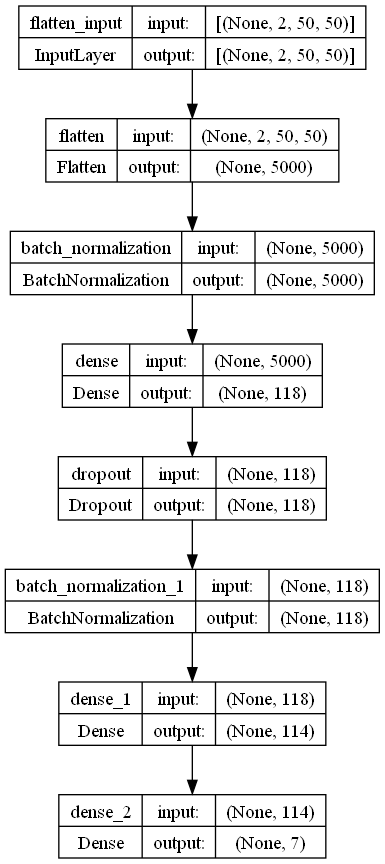

In [23]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [24]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [25]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [26]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [27]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [28]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 80
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [29]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 1s 11ms/step - loss: 10.4582 - a_1: 2.2795 - a_2: 2.2898 - b_1: 1.7454 - b_2: 1.7880 - d_1: 1.4675 - d_2: 1.3113 - n: 1.2324 - mean_metric: 0.3793 - val_loss: 6.8588 - val_a_1: 2.2102 - val_a_2: 2.2090 - val_b_1: 1.8966 - val_b_2: 2.0336 - val_d_1: 1.4289 - val_d_2: 1.5540 - val_n: 1.2105 - val_mean_metric: 0.3941 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 1s 8ms/step - loss: 4.9052 - a_1: 1.8153 - a_2: 1.8290 - b_1: 1.4169 - b_2: 1.4241 - d_1: 1.1688 - d_2: 1.1554 - n: 1.1972 - mean_metric: 0.3133 - val_loss: 4.9558 - val_a_1: 1.9159 - val_a_2: 1.9587 - val_b_1: 1.5728 - val_b_2: 1.6809 - val_d_1: 1.2077 - val_d_2: 1.1760 - val_n: 1.1920 - val_mean_metric: 0.3363 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 1s 8ms/step - loss: 4.4043 - a_1: 1.6923 - a_2: 1.6811 - b_1: 1.3553 - b_2: 1.3843 - d_1: 1.1339 - d_2: 1.1246 - n: 1.1868 - mean_metric: 0.2992 - val_loss: 4.2757 - val_a_1: 1.7692 

70/70 [==============================] - 1s 8ms/step - loss: 2.4288 - a_1: 1.1884 - a_2: 1.1416 - b_1: 1.0120 - b_2: 1.0124 - d_1: 0.9213 - d_2: 0.8880 - n: 0.8155 - mean_metric: 0.2185 - val_loss: 2.0878 - val_a_1: 1.0429 - val_a_2: 1.0642 - val_b_1: 0.8401 - val_b_2: 0.8848 - val_d_1: 0.7792 - val_d_2: 0.7855 - val_n: 0.7663 - val_mean_metric: 0.1936 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.4447 - a_1: 1.1925 - a_2: 1.1724 - b_1: 0.9999 - b_2: 1.0218 - d_1: 0.9135 - d_2: 0.8917 - n: 0.8189 - mean_metric: 0.2195 - val_loss: 2.0213 - val_a_1: 0.9968 - val_a_2: 1.0019 - val_b_1: 0.7977 - val_b_2: 0.8794 - val_d_1: 0.7945 - val_d_2: 0.8451 - val_n: 0.7658 - val_mean_metric: 0.1911 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.4183 - a_1: 1.1762 - a_2: 1.1523 - b_1: 1.0213 - b_2: 1.0090 - d_1: 0.9195 - d_2: 0.8843 - n: 0.8148 - mean_metric: 0.2185 - val_loss: 2.0517 - val_a_1: 1.0694 - val_a_2: 1.

70/70 [==============================] - 1s 8ms/step - loss: 2.2177 - a_1: 1.1260 - a_2: 1.1073 - b_1: 0.9771 - b_2: 0.9934 - d_1: 0.8755 - d_2: 0.8496 - n: 0.7398 - mean_metric: 0.2088 - val_loss: 1.8662 - val_a_1: 0.9279 - val_a_2: 1.0074 - val_b_1: 0.8150 - val_b_2: 0.8314 - val_d_1: 0.7817 - val_d_2: 0.7445 - val_n: 0.6770 - val_mean_metric: 0.1817 - lr: 9.9570e-04
Epoch 86/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.2441 - a_1: 1.1505 - a_2: 1.1053 - b_1: 0.9841 - b_2: 0.9813 - d_1: 0.8931 - d_2: 0.8579 - n: 0.7440 - mean_metric: 0.2103 - val_loss: 1.8469 - val_a_1: 0.8943 - val_a_2: 1.0368 - val_b_1: 0.8334 - val_b_2: 0.8449 - val_d_1: 0.7548 - val_d_2: 0.7098 - val_n: 0.6635 - val_mean_metric: 0.1802 - lr: 9.9462e-04
Epoch 87/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.1948 - a_1: 1.1296 - a_2: 1.0847 - b_1: 0.9700 - b_2: 0.9908 - d_1: 0.8779 - d_2: 0.8465 - n: 0.7355 - mean_metric: 0.2077 - val_loss: 1.8206 - val_a_1: 0.9086 - val

70/70 [==============================] - 1s 8ms/step - loss: 2.1105 - a_1: 1.1161 - a_2: 1.0867 - b_1: 0.9539 - b_2: 0.9675 - d_1: 0.8442 - d_2: 0.8251 - n: 0.7158 - mean_metric: 0.2038 - val_loss: 1.7468 - val_a_1: 0.9189 - val_a_2: 0.9753 - val_b_1: 0.8039 - val_b_2: 0.7792 - val_d_1: 0.7581 - val_d_2: 0.6868 - val_n: 0.6409 - val_mean_metric: 0.1748 - lr: 9.5050e-04
Epoch 128/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.0894 - a_1: 1.1075 - a_2: 1.0666 - b_1: 0.9463 - b_2: 0.9719 - d_1: 0.8449 - d_2: 0.8341 - n: 0.7088 - mean_metric: 0.2029 - val_loss: 1.7051 - val_a_1: 0.8827 - val_a_2: 0.9399 - val_b_1: 0.7862 - val_b_2: 0.7784 - val_d_1: 0.7345 - val_d_2: 0.7076 - val_n: 0.6507 - val_mean_metric: 0.1722 - lr: 9.4942e-04
Epoch 129/1000
70/70 [==============================] - 1s 9ms/step - loss: 2.0957 - a_1: 1.1104 - a_2: 1.0836 - b_1: 0.9491 - b_2: 0.9549 - d_1: 0.8592 - d_2: 0.8164 - n: 0.7070 - mean_metric: 0.2029 - val_loss: 1.7267 - val_a_1: 0.8726 - v

70/70 [==============================] - 1s 8ms/step - loss: 2.0164 - a_1: 1.0821 - a_2: 1.0573 - b_1: 0.9294 - b_2: 0.9529 - d_1: 0.8387 - d_2: 0.8282 - n: 0.6997 - mean_metric: 0.2000 - val_loss: 1.6798 - val_a_1: 0.8591 - val_a_2: 0.9618 - val_b_1: 0.7751 - val_b_2: 0.8021 - val_d_1: 0.7579 - val_d_2: 0.7014 - val_n: 0.6491 - val_mean_metric: 0.1730 - lr: 9.0530e-04
Epoch 170/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.0102 - a_1: 1.0935 - a_2: 1.0729 - b_1: 0.9191 - b_2: 0.9457 - d_1: 0.8273 - d_2: 0.8105 - n: 0.6933 - mean_metric: 0.1992 - val_loss: 1.6775 - val_a_1: 0.8671 - val_a_2: 0.9965 - val_b_1: 0.7658 - val_b_2: 0.7837 - val_d_1: 0.7598 - val_d_2: 0.6902 - val_n: 0.6229 - val_mean_metric: 0.1724 - lr: 9.0423e-04
Epoch 171/1000
70/70 [==============================] - 1s 8ms/step - loss: 2.0392 - a_1: 1.1083 - a_2: 1.0663 - b_1: 0.9369 - b_2: 0.9406 - d_1: 0.8446 - d_2: 0.8245 - n: 0.6988 - mean_metric: 0.2011 - val_loss: 1.7055 - val_a_1: 0.9244 - v

70/70 [==============================] - 1s 8ms/step - loss: 1.9806 - a_1: 1.0684 - a_2: 1.0564 - b_1: 0.9256 - b_2: 0.9477 - d_1: 0.8322 - d_2: 0.8174 - n: 0.7061 - mean_metric: 0.1989 - val_loss: 1.6416 - val_a_1: 0.8828 - val_a_2: 0.9529 - val_b_1: 0.7881 - val_b_2: 0.7671 - val_d_1: 0.7323 - val_d_2: 0.6852 - val_n: 0.6425 - val_mean_metric: 0.1713 - lr: 8.6011e-04
Epoch 212/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.9924 - a_1: 1.0985 - a_2: 1.0548 - b_1: 0.9341 - b_2: 0.9414 - d_1: 0.8352 - d_2: 0.8103 - n: 0.6886 - mean_metric: 0.1992 - val_loss: 1.6505 - val_a_1: 0.8585 - val_a_2: 0.9980 - val_b_1: 0.7712 - val_b_2: 0.7672 - val_d_1: 0.7604 - val_d_2: 0.6807 - val_n: 0.6444 - val_mean_metric: 0.1722 - lr: 8.5903e-04
Epoch 213/1000
70/70 [==============================] - 1s 9ms/step - loss: 1.9763 - a_1: 1.0862 - a_2: 1.0688 - b_1: 0.9246 - b_2: 0.9455 - d_1: 0.8362 - d_2: 0.8186 - n: 0.6805 - mean_metric: 0.1992 - val_loss: 1.6194 - val_a_1: 0.8586 - v

... (14 outputs left out)

70/70 [==============================] - 1s 8ms/step - loss: 1.5868 - a_1: 1.0087 - a_2: 0.9839 - b_1: 0.8583 - b_2: 0.8768 - d_1: 0.7512 - d_2: 0.7468 - n: 0.6442 - mean_metric: 0.1838 - val_loss: 1.3024 - val_a_1: 0.8141 - val_a_2: 0.8832 - val_b_1: 0.7212 - val_b_2: 0.7019 - val_d_1: 0.6474 - val_d_2: 0.6377 - val_n: 0.5838 - val_mean_metric: 0.1568 - lr: 1.8217e-04
Epoch 842/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5870 - a_1: 0.9990 - a_2: 0.9946 - b_1: 0.8638 - b_2: 0.8801 - d_1: 0.7476 - d_2: 0.7483 - n: 0.6437 - mean_metric: 0.1840 - val_loss: 1.3100 - val_a_1: 0.8207 - val_a_2: 0.8995 - val_b_1: 0.7258 - val_b_2: 0.7079 - val_d_1: 0.6455 - val_d_2: 0.6407 - val_n: 0.5826 - val_mean_metric: 0.1578 - lr: 1.8110e-04
Epoch 843/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5833 - a_1: 1.0074 - a_2: 0.9935 - b_1: 0.8665 - b_2: 0.8634 - d_1: 0.7525 - d_2: 0.7443 - n: 0.6482 - mean_metric: 0.1839 - val_loss: 1.3046 - val_a_1: 0.8132 - v

70/70 [==============================] - 1s 8ms/step - loss: 1.5643 - a_1: 1.0011 - a_2: 0.9908 - b_1: 0.8450 - b_2: 0.8603 - d_1: 0.7512 - d_2: 0.7461 - n: 0.6382 - mean_metric: 0.1826 - val_loss: 1.2943 - val_a_1: 0.8175 - val_a_2: 0.8856 - val_b_1: 0.7209 - val_b_2: 0.7040 - val_d_1: 0.6496 - val_d_2: 0.6420 - val_n: 0.5824 - val_mean_metric: 0.1572 - lr: 1.3698e-04
Epoch 884/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5791 - a_1: 1.0101 - a_2: 0.9966 - b_1: 0.8640 - b_2: 0.8637 - d_1: 0.7516 - d_2: 0.7433 - n: 0.6434 - mean_metric: 0.1839 - val_loss: 1.2862 - val_a_1: 0.8054 - val_a_2: 0.8801 - val_b_1: 0.7164 - val_b_2: 0.7054 - val_d_1: 0.6497 - val_d_2: 0.6399 - val_n: 0.5769 - val_mean_metric: 0.1563 - lr: 1.3590e-04
Epoch 885/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5681 - a_1: 1.0022 - a_2: 0.9982 - b_1: 0.8500 - b_2: 0.8720 - d_1: 0.7476 - d_2: 0.7406 - n: 0.6472 - mean_metric: 0.1834 - val_loss: 1.2916 - val_a_1: 0.8145 - v

70/70 [==============================] - 1s 8ms/step - loss: 1.5504 - a_1: 0.9912 - a_2: 0.9941 - b_1: 0.8604 - b_2: 0.8637 - d_1: 0.7504 - d_2: 0.7358 - n: 0.6461 - mean_metric: 0.1829 - val_loss: 1.2670 - val_a_1: 0.8021 - val_a_2: 0.8781 - val_b_1: 0.7164 - val_b_2: 0.7042 - val_d_1: 0.6478 - val_d_2: 0.6379 - val_n: 0.5786 - val_mean_metric: 0.1560 - lr: 9.1783e-05
Epoch 926/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5565 - a_1: 1.0046 - a_2: 0.9917 - b_1: 0.8573 - b_2: 0.8552 - d_1: 0.7475 - d_2: 0.7459 - n: 0.6521 - mean_metric: 0.1833 - val_loss: 1.2677 - val_a_1: 0.8097 - val_a_2: 0.8721 - val_b_1: 0.7197 - val_b_2: 0.7057 - val_d_1: 0.6478 - val_d_2: 0.6410 - val_n: 0.5772 - val_mean_metric: 0.1563 - lr: 9.0707e-05
Epoch 927/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5496 - a_1: 0.9999 - a_2: 0.9897 - b_1: 0.8545 - b_2: 0.8620 - d_1: 0.7460 - d_2: 0.7424 - n: 0.6473 - mean_metric: 0.1828 - val_loss: 1.2650 - val_a_1: 0.8117 - v

70/70 [==============================] - 1s 8ms/step - loss: 1.5365 - a_1: 0.9980 - a_2: 0.9900 - b_1: 0.8594 - b_2: 0.8672 - d_1: 0.7478 - d_2: 0.7373 - n: 0.6398 - mean_metric: 0.1828 - val_loss: 1.2474 - val_a_1: 0.8061 - val_a_2: 0.8600 - val_b_1: 0.7158 - val_b_2: 0.7039 - val_d_1: 0.6442 - val_d_2: 0.6376 - val_n: 0.5740 - val_mean_metric: 0.1553 - lr: 4.6587e-05
Epoch 968/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5384 - a_1: 1.0004 - a_2: 1.0036 - b_1: 0.8414 - b_2: 0.8602 - d_1: 0.7477 - d_2: 0.7327 - n: 0.6456 - mean_metric: 0.1826 - val_loss: 1.2440 - val_a_1: 0.8078 - val_a_2: 0.8593 - val_b_1: 0.7146 - val_b_2: 0.6984 - val_d_1: 0.6444 - val_d_2: 0.6388 - val_n: 0.5748 - val_mean_metric: 0.1552 - lr: 4.5511e-05
Epoch 969/1000
70/70 [==============================] - 1s 8ms/step - loss: 1.5281 - a_1: 0.9970 - a_2: 0.9828 - b_1: 0.8581 - b_2: 0.8603 - d_1: 0.7456 - d_2: 0.7408 - n: 0.6434 - mean_metric: 0.1824 - val_loss: 1.2454 - val_a_1: 0.8067 - v

# Analizamos accuracy y loss

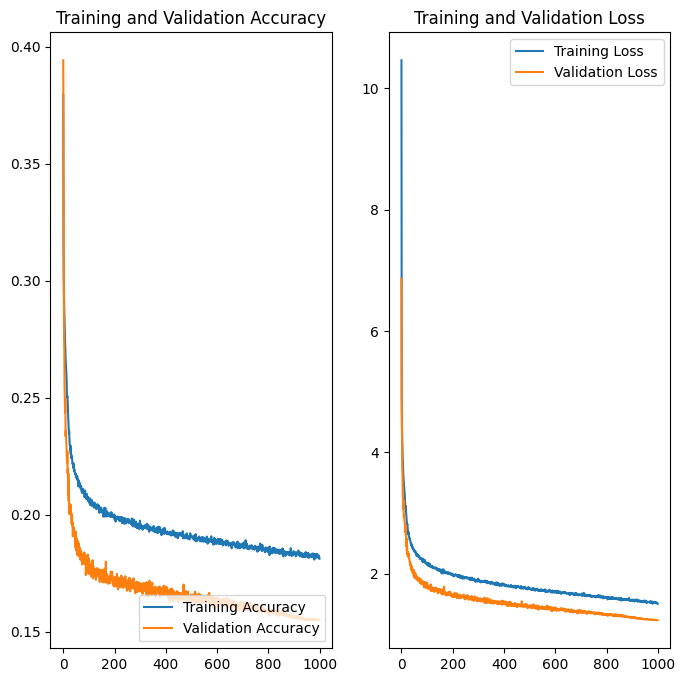

In [31]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

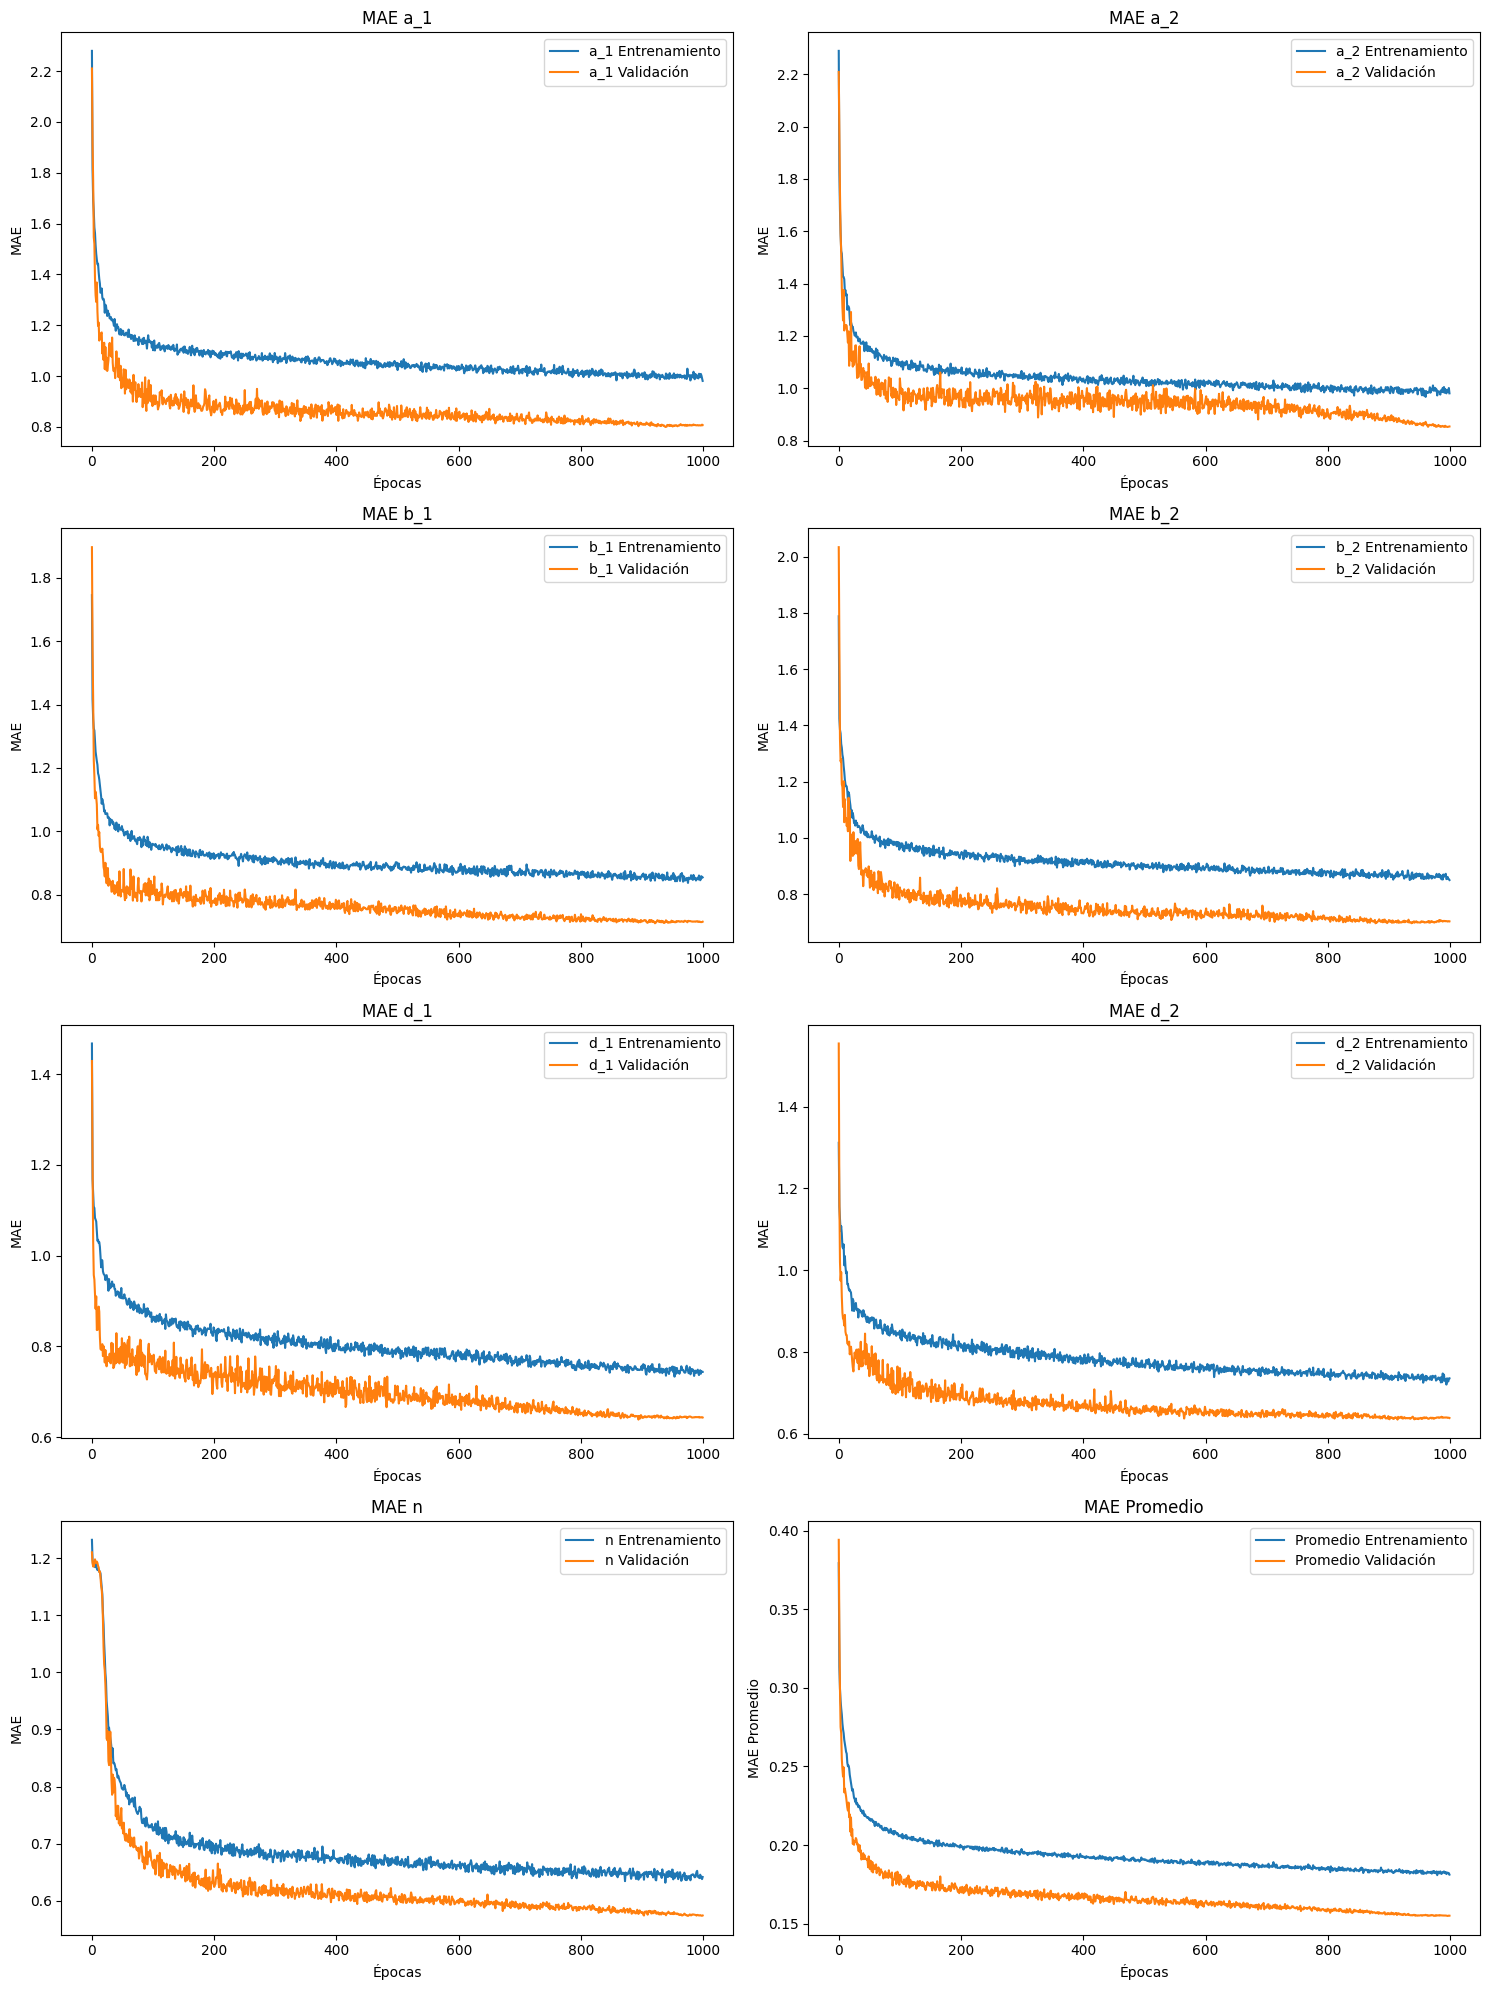

In [32]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [33]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 0s 1ms/step - loss: 1.3301 - a_1: 0.8312 - a_2: 0.8806 - b_1: 0.7493 - b_2: 0.7493 - d_1: 0.6874 - d_2: 0.6557 - n: 0.5658 - mean_metric: 0.1610


In [34]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 788us/step


In [35]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.7318687328938395, Desviación estándar del error: 1.006988517457889, Error absoluto máximo: 6.231424331665039


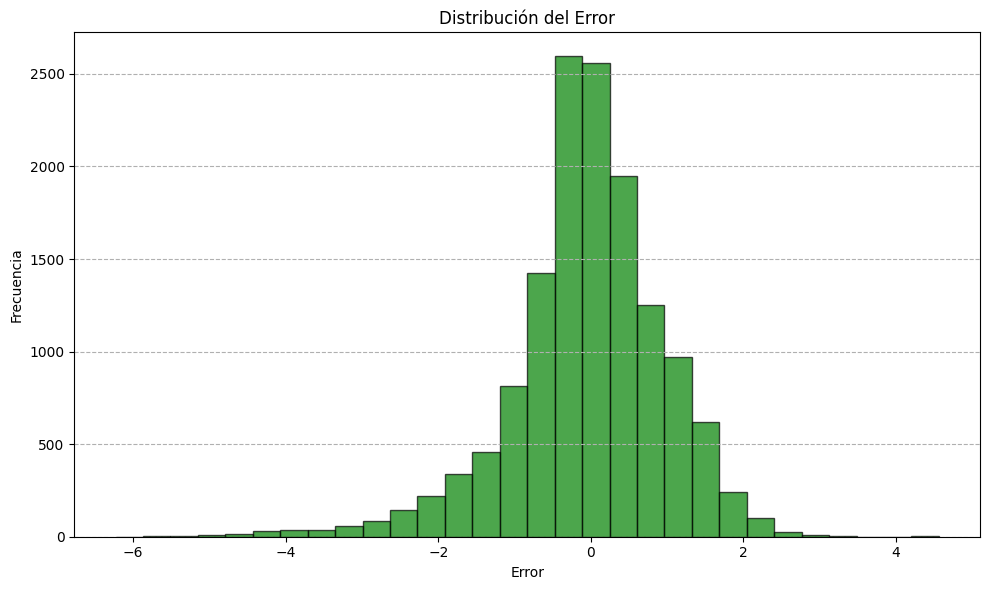

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [37]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")

MAE relativo: 0.17170237581984663
Desviación estándar del error relativo: 0.20791932080866332
Error absoluto máximo relativo: 1.7633267732766957


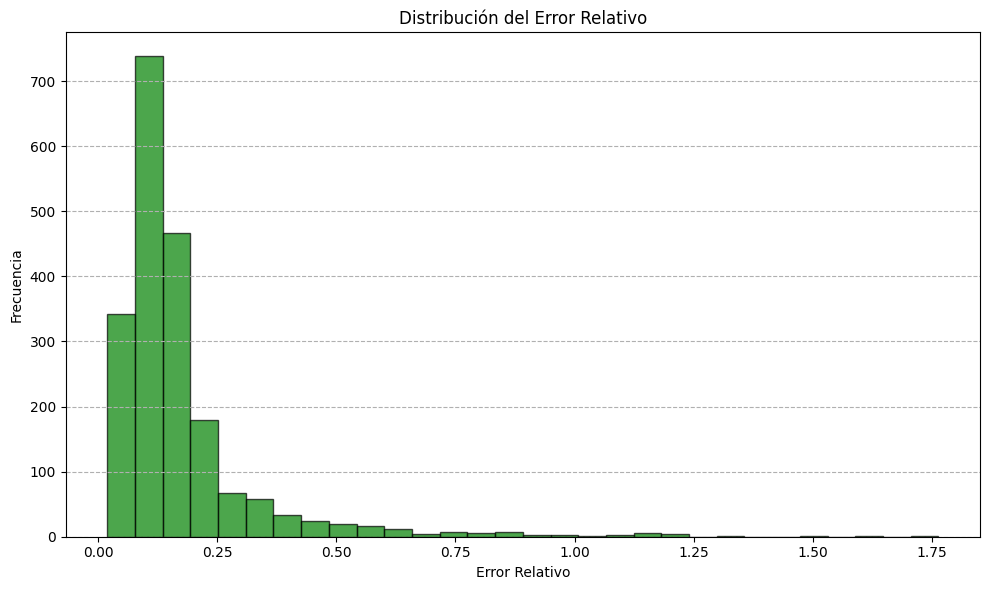

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos accuracy y loss

In [39]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales con ruido/grid50_traj100/historycampvec50.csv', index=False)

# Guardamos el modelo

In [40]:
path_to_save = '../../../trained_models_noisy/grid50_traj100'

In [41]:
model.save(path_to_save + '/campovectorial50.h5')

# Importamos el modelo

In [1]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [2]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [3]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_noisy/grid50_traj100/campovectorial50.h5',
                                   custom_objects= custom_objects)

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.1
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [45]:
import random 
import matplotlib.pyplot as plt
for i in range(0, 1):
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef = [a1, a2, b1, b2, d1, d2, n]

    for i_ci in range(0, 1):
        x_range_neg = 0
        x_range_pos = 10
        y_range_neg = 0
        y_range_pos =10

        y1 = np.linspace(x_range_neg, x_range_pos, 50)
        y2 = np.linspace(y_range_neg, y_range_pos, 50)

        Y1, Y2 = np.meshgrid(y1, y2)

        t1 = 0

        NI, NJ = Y1.shape
        u, v = np.zeros((NI, NJ)), np.zeros((NI, NJ))

        for i in range(NI):
            for j in range(NJ):
                # asignar a cada ODE a un elemento de vector
                X = Y1[i, j]
                Y = Y2[i, j]
                noise1 = np.random.normal(0, .5)
                noise2 = np.random.normal(0, .5)

                # definimos cada ODE
                dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
                dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2

                u[i, j], v[i, j] = dX_dt, dY_dt

        M = (np.hypot(u, v))
        u1, v1 = u, v
        u /= M
        v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print(coef)

    
campvec = np.array(campvec)
coef = np.array(coef)



[10, 9, 10, 1, 7, 2, 1]


In [46]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [47]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 46ms/step
[[8. 7. 8. 1. 6. 1. 1.]]


## Encontramos puntos de equilibrio datos reales

In [48]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(1.8963947895569742, 2.0536556053150483)


## Graficamos con los coeficientes reales

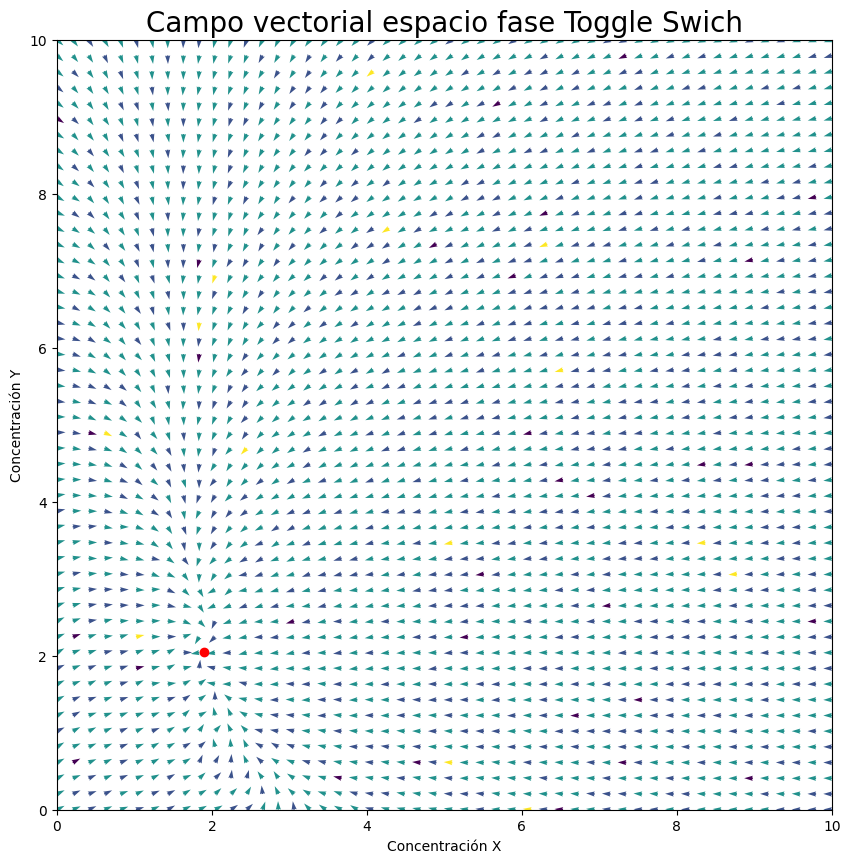

In [49]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]

y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')
plt.show()

## Encontramos puntos de equilibrio datos predecidos

In [50]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(1.6186524130110247, 3.6731306397222006)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

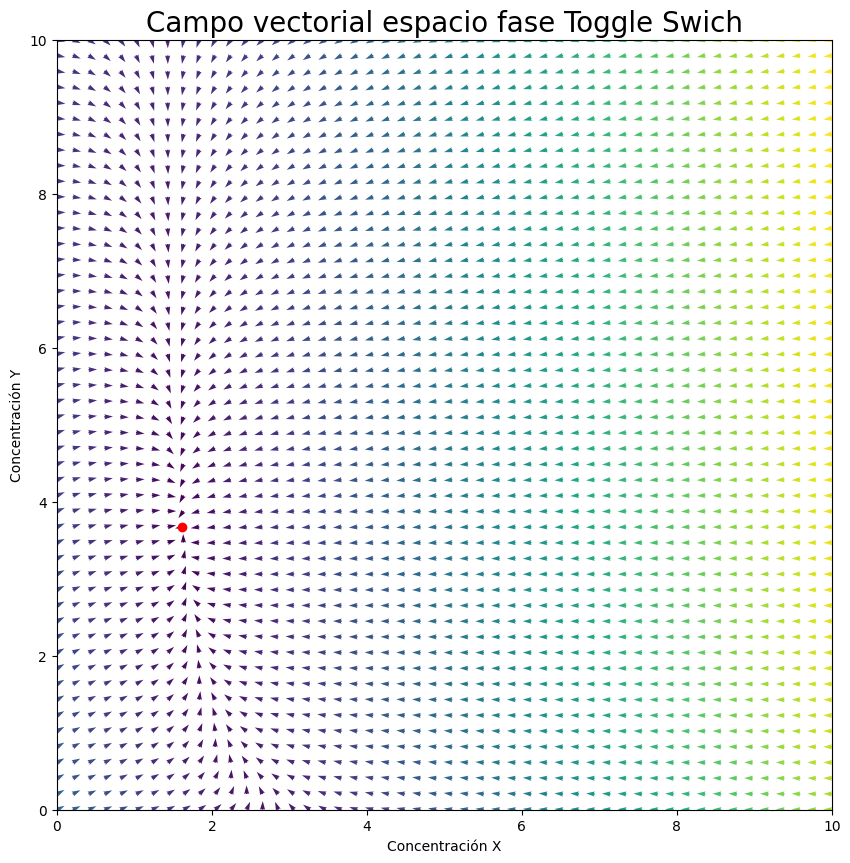

In [51]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

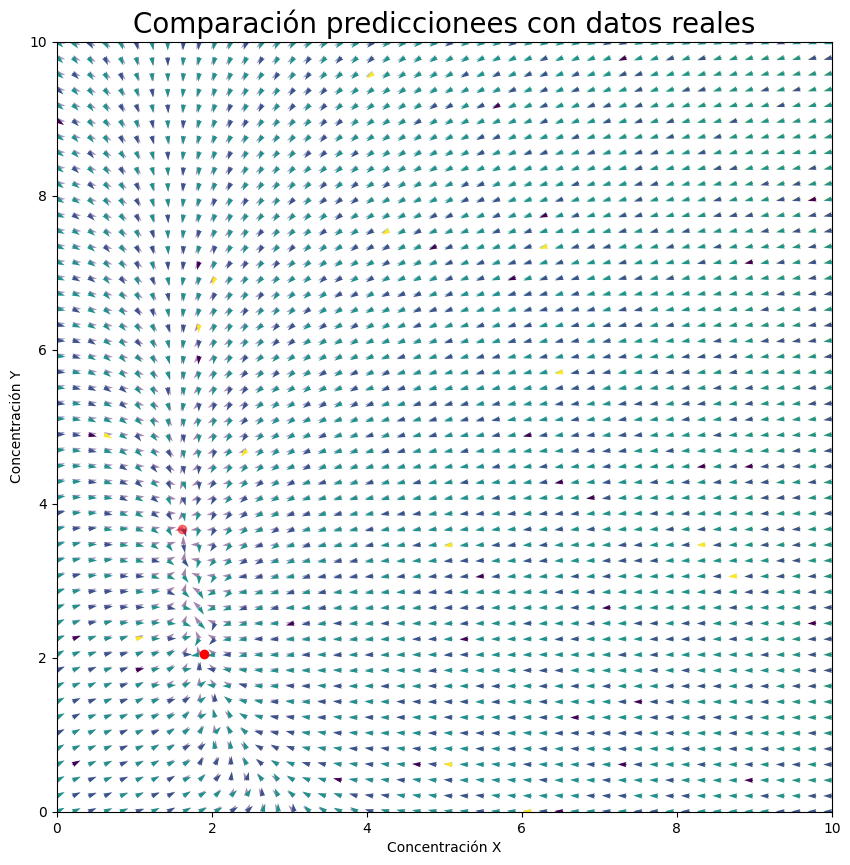

In [52]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Comparación prediccionees con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

59.79322147724877


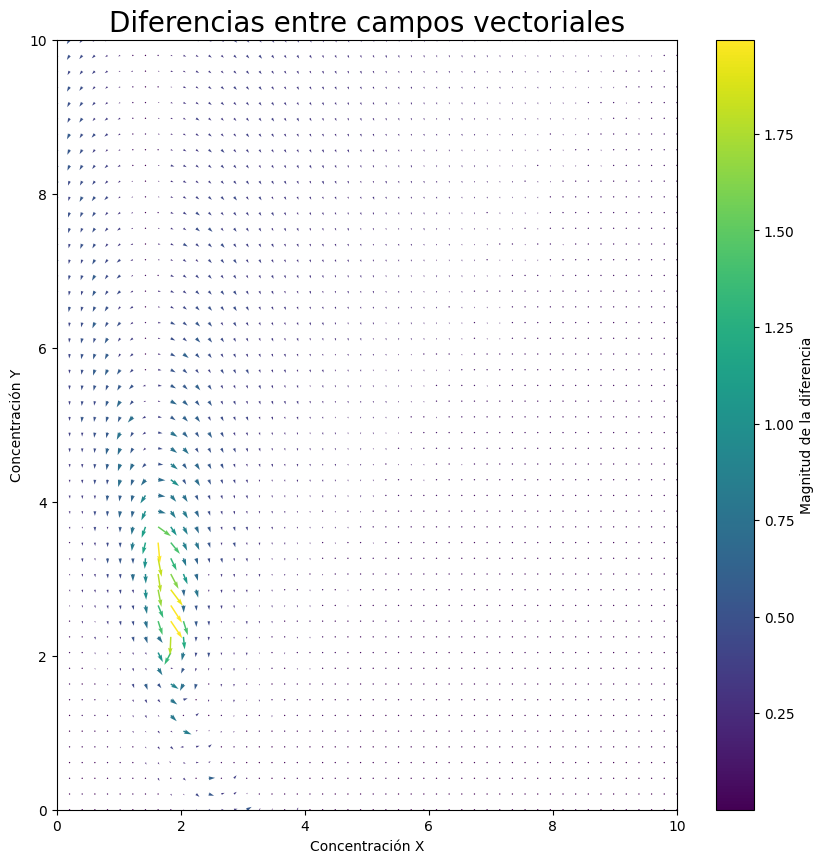

In [53]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

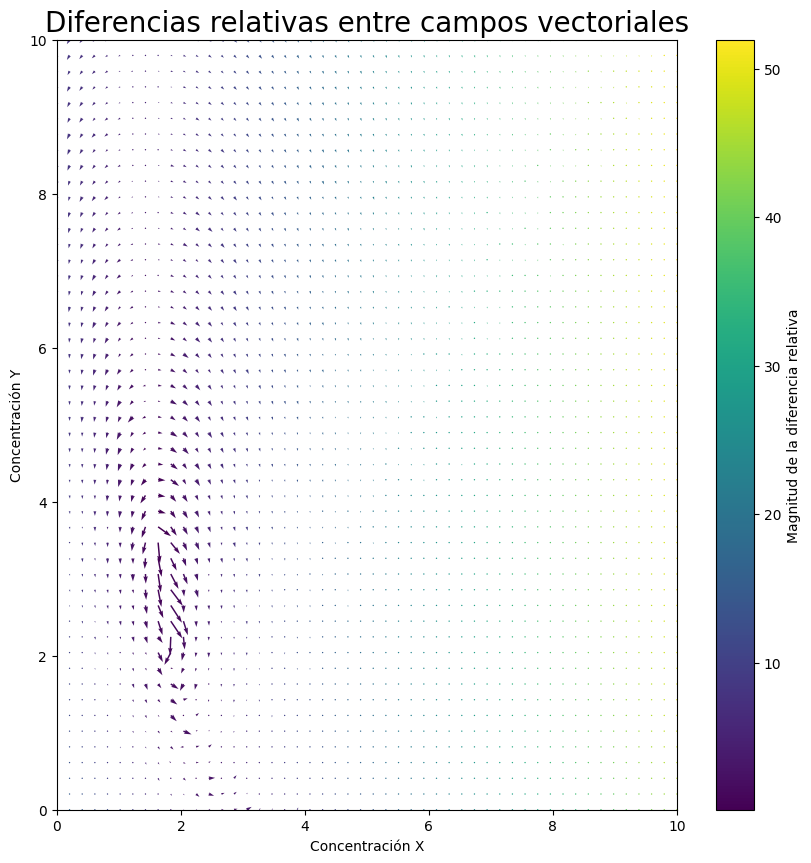

In [54]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [55]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 84.68%


## Simulamos n veces

In [4]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(1000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def ftrue(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape
    
    
    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)
            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2
            u[i, j], v[i, j] = dX_dt, dY_dt

    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 50)
    y2pred = np.linspace(y_range_neg, y_range_pos, 50)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred
    
    utrue, vtrue = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    utrue, vtrue = ftrue(t1, [Y1, Y2])
    Mtrue = (np.hypot(utrue, vtrue))
    utrue /= Mtrue
    vtrue /= Mtrue  

 # Calculamos las diferencias
    u_diff = utrue - upred
    v_diff = vtrue - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 63ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 0.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 13.36%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 68.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 2.80%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 88.92%
--------------------------------------------
1/1 [===========================

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 73.76%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 9.08%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 28.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 16.68%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 71.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de pu

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 54.44%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 79.92%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 52.48%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 43.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 4.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de pu

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 66.52%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 1.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 70.72%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 14.52%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 12.64%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje 

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 19.92%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 96.32%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 38.92%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 16.44%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 61.60%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 30.12%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 1.56%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 81.20%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 65.04%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 20.08%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje 

... (13 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 837 es 13.68%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 838 es 44.72%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 839 es 11.40%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 840 es 5.64%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 841 es 43.28%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje 

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 881 es 4.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 882 es 6.72%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 883 es 59.64%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 884 es 53.08%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 885 es 29.48%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje d

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 925 es 87.12%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 926 es 70.56%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 927 es 4.60%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 928 es 4.68%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 929 es 89.32%
--------------------------------------------
1/1 [==============================] - 0s 18ms/step
El porcentaje d

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 969 es 93.84%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 970 es 40.28%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 971 es 13.04%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 972 es 20.28%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 973 es 93.36%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje

El promedio de los porcentajes es 88.53%


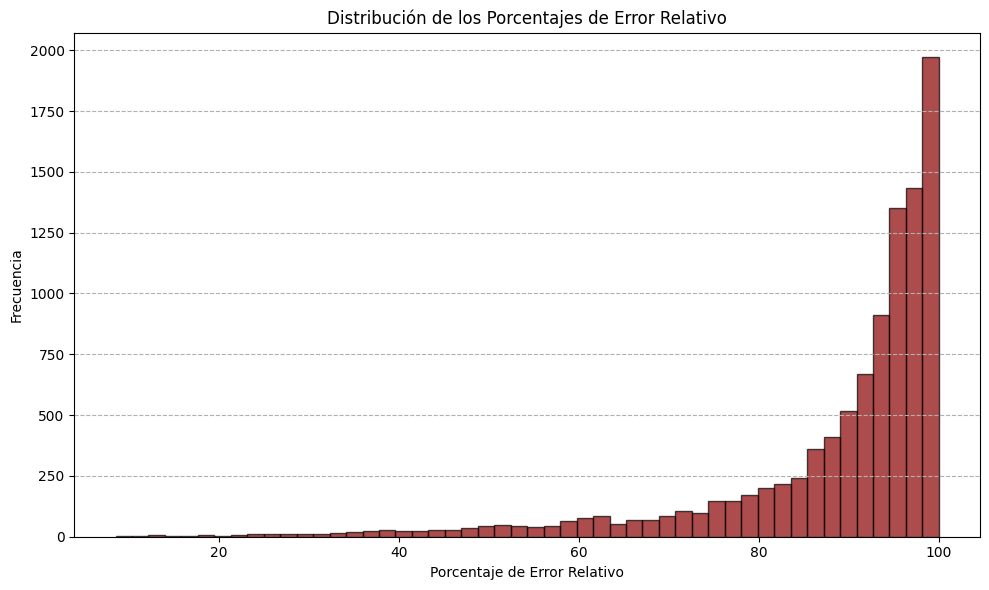

In [57]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()